# The Growing Importance of Remittances in Vietnam
**Thesis:** since 2000 remittances have become a major and persistent source of external finance for Vietnam, reaching a scale comparable to FDI and placing Vietnam among the largest remittance recipients in ASEAN.

Three tests: (1) growth over time, (2) scale versus FDI, (3) position within ASEAN. A fourth section adds a caveat the headline numbers hide: remittances relative to GDP.

In [1]:
import sys; sys.path.insert(0, "..")
import pandas as pd
from IPython.display import Image, display
from src import analysis, data, viz

pd.options.display.float_format = "{:,.2f}".format
panel = data.load_panel()
panel[panel.Code == "VNM"].tail()

,Country,Code,Year,Remittances,FDI,GDP,Remit_pct_GDP,FDI_pct_GDP,Remit_to_FDI,Remit_YoY_pct
270,Vietnam,VNM,2020,"10,714.57","15,800.00","346,615.74",3.09,4.56,0.68,-1.57
271,Vietnam,VNM,2021,"12,722.09","15,660.00","366,474.75",3.47,4.27,0.81,18.74
272,Vietnam,VNM,2022,"13,200.00","17,900.00","413,445.23",3.19,4.33,0.74,3.76
273,Vietnam,VNM,2023,"14,000.00","18,500.00","433,805.04",3.23,4.26,0.76,6.06
274,Vietnam,VNM,2024,"16,000.00","20,170.00","476,324.57",3.36,4.23,0.79,14.29


## 1. Growth over time

2000: 1,585  ->  2024: 16,000 US$ million (10.1x, CAGR 10.1%)
Years with a year-on-year decline: [2001, 2009, 2012, 2015, 2020]


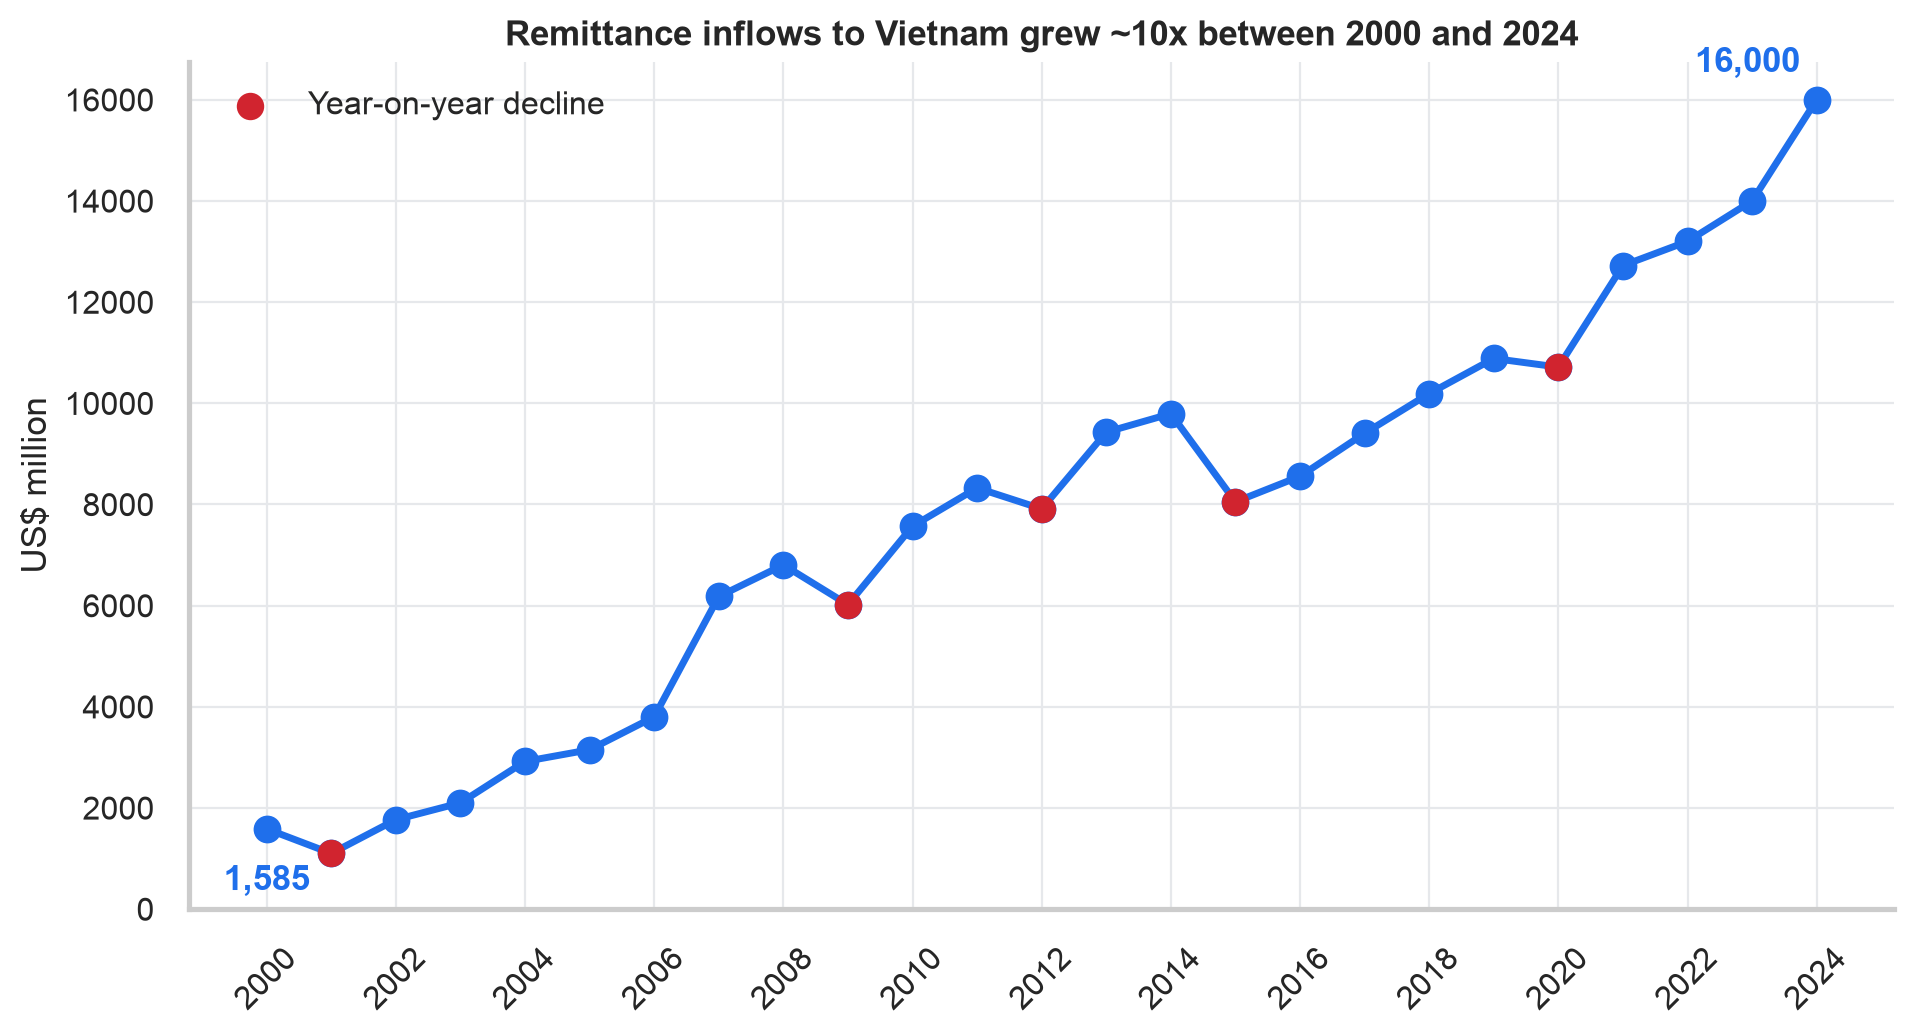

In [2]:
h = analysis.vietnam_headline(panel)
print(f"2000: {h['remit_start']:,.0f}  ->  2024: {h['remit_end']:,.0f} US$ million "
      f"({h['multiple']:.1f}x, CAGR {h['cagr_pct']:.1f}%)")
print("Years with a year-on-year decline:", h["decline_years"])
display(Image(viz.vietnam_trend(panel)))

Every dip (2001, 2009, 2012, 2015, 2020) was followed by recovery, so the upward trend is persistent rather than a short-lived spike.

## 2. Scale versus FDI

Years remittances > FDI: [2000, 2002, 2003, 2004, 2005, 2006, 2011, 2013, 2014]
2024 remittances / FDI = 0.79


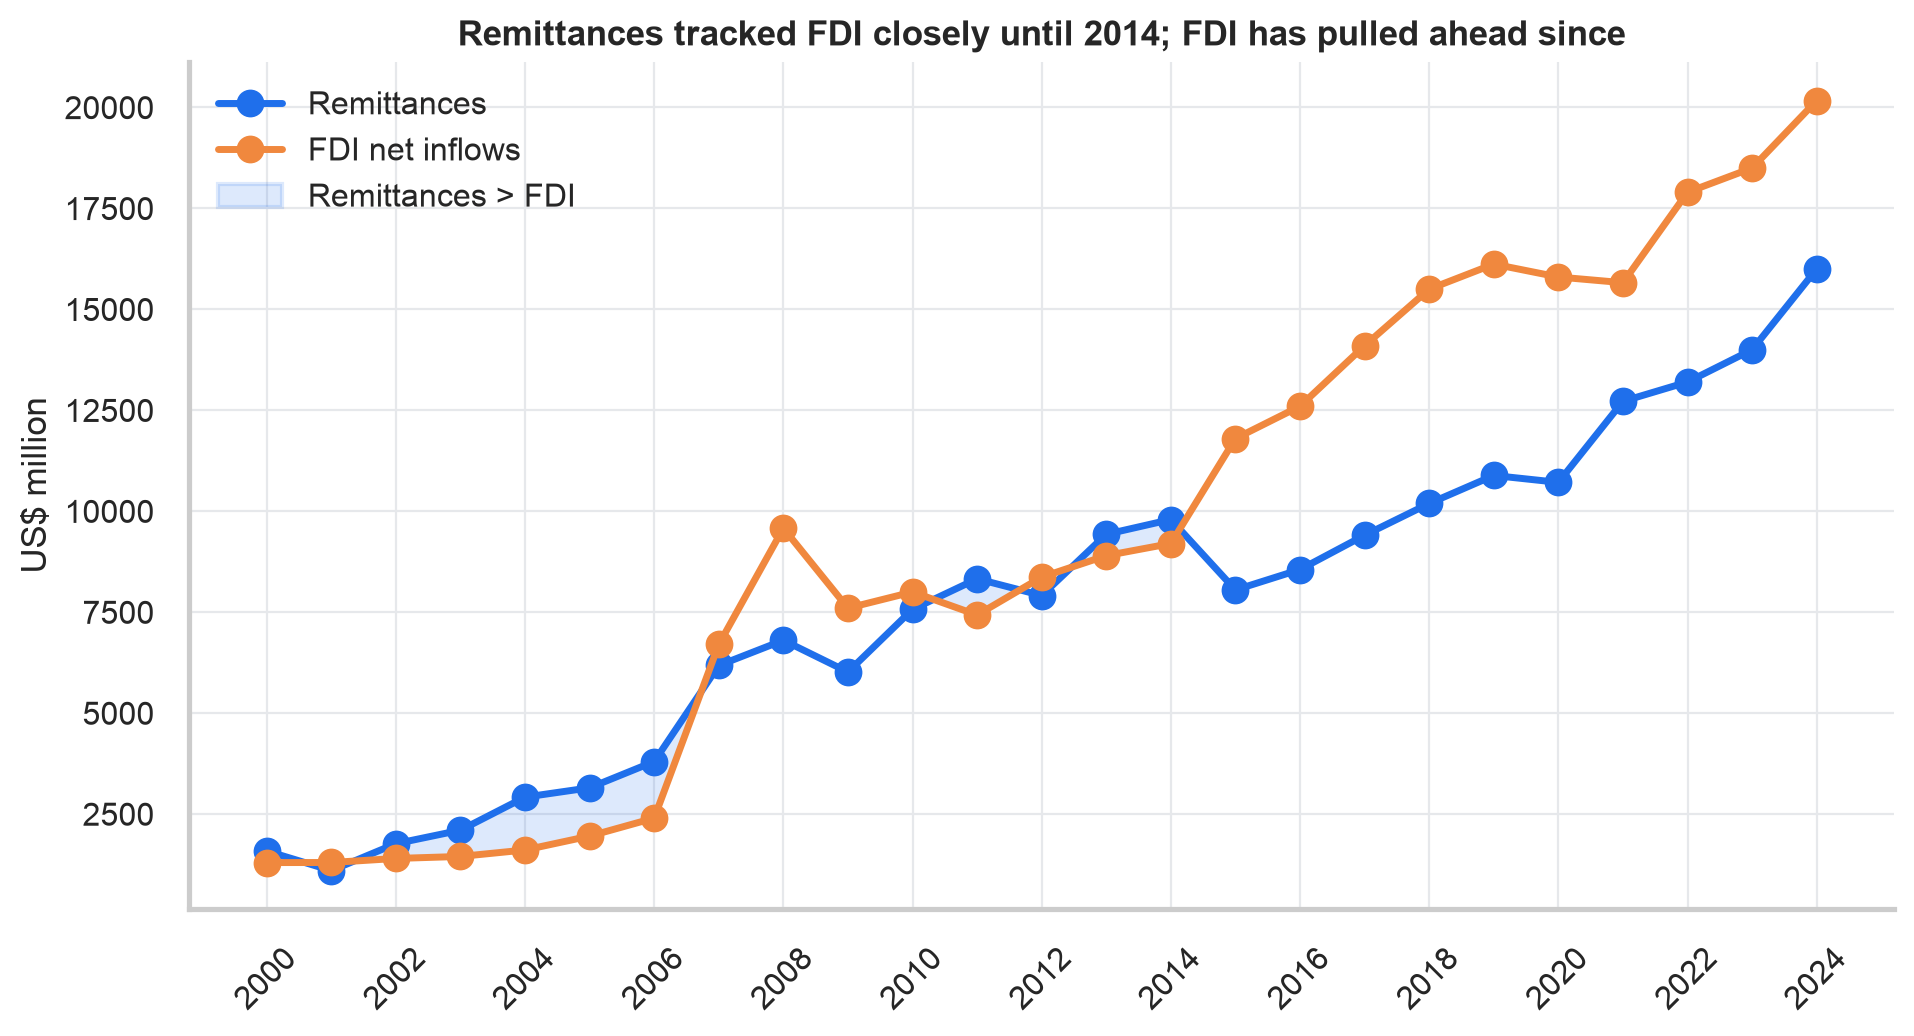

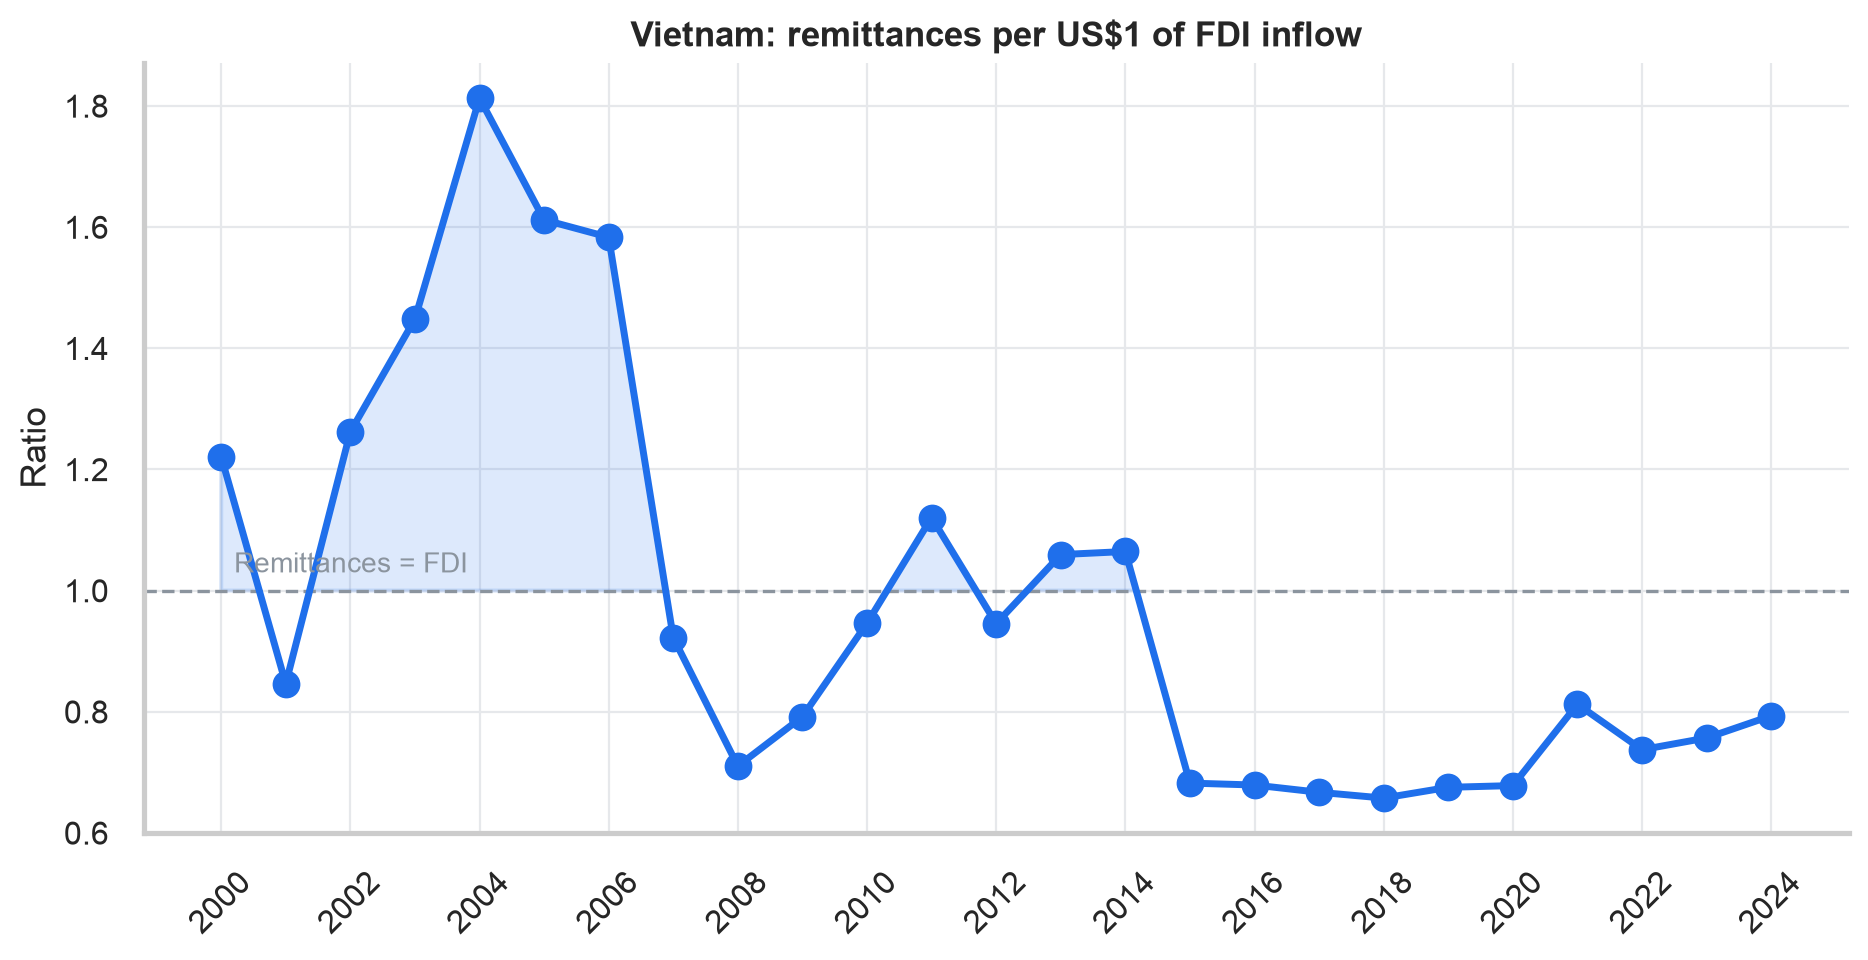

In [3]:
print("Years remittances > FDI:", h["years_remit_above_fdi"])
print(f"2024 remittances / FDI = {h['remit_to_fdi_end']:.2f}")
display(Image(viz.remittances_vs_fdi(panel)))
display(Image(viz.remittance_fdi_ratio(panel)))

Remittances were at or above FDI in 9 of the first 15 years; since 2015 FDI has been larger, but in 2024 remittances were still ~79% of FDI, the same order of magnitude.

## 3. Vietnam within ASEAN

,Rank,Country,Remittances,Share_of_ASEAN_pct,Remit_pct_GDP,FDI,Remit_to_FDI
0,1,Philippines,"40,279.41",45.79,8.72,"9,398.33",4.29
1,2,Indonesia,"16,038.37",18.23,1.15,"24,275.45",0.66
2,3,Vietnam,"16,000.00",18.19,3.36,"20,170.00",0.79
3,4,Thailand,"9,584.46",10.90,1.81,"14,302.16",0.67
4,5,Cambodia,"2,827.92",3.21,6.10,"4,394.65",0.64
5,6,Malaysia,"1,605.28",1.82,0.38,"15,593.25",0.10
6,7,Myanmar,"1,150.00",1.31,1.55,"1,095.32",1.05
7,8,Lao PDR,260.00,0.30,1.58,988.46,0.26
8,9,Timor-Leste,219.57,0.25,11.77,225.47,0.97
9,10,Brunei,1.00,0.00,0.01,29.06,0.03


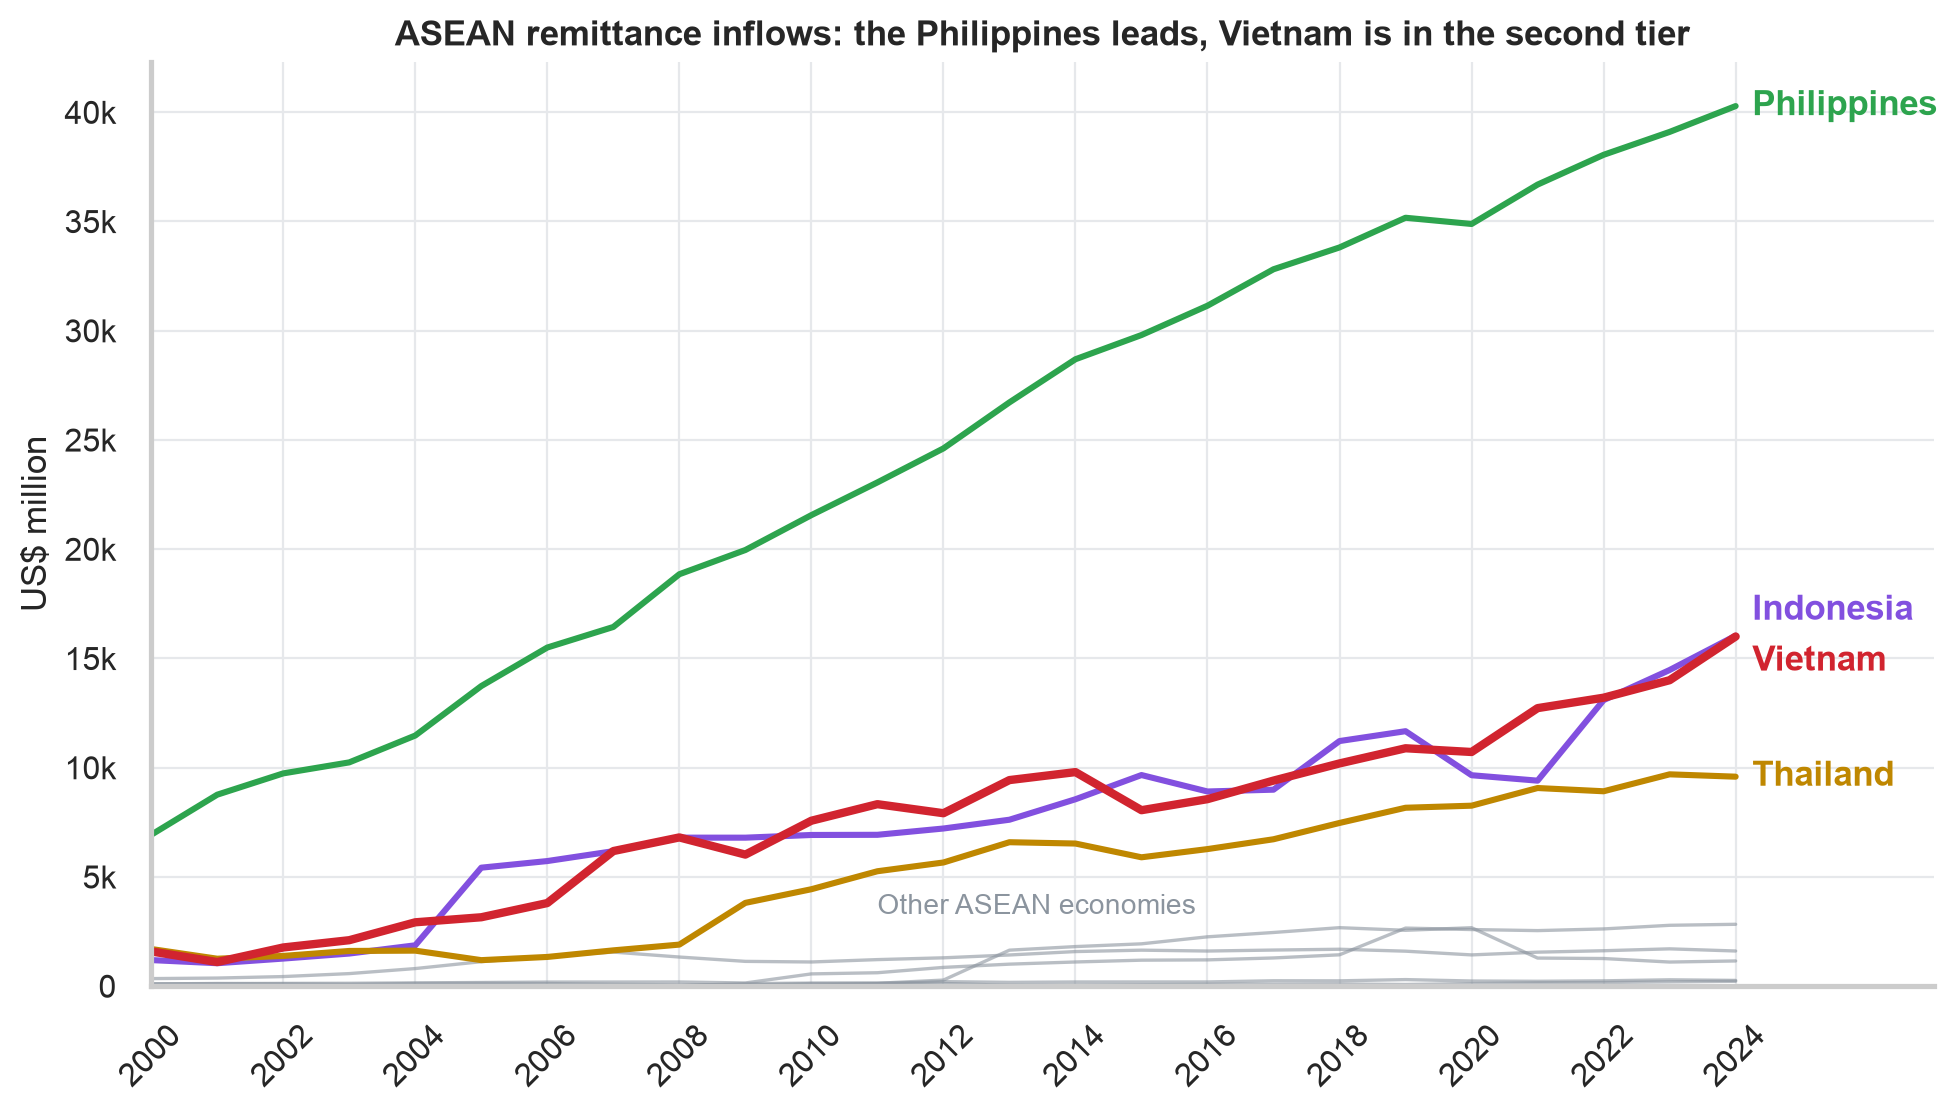

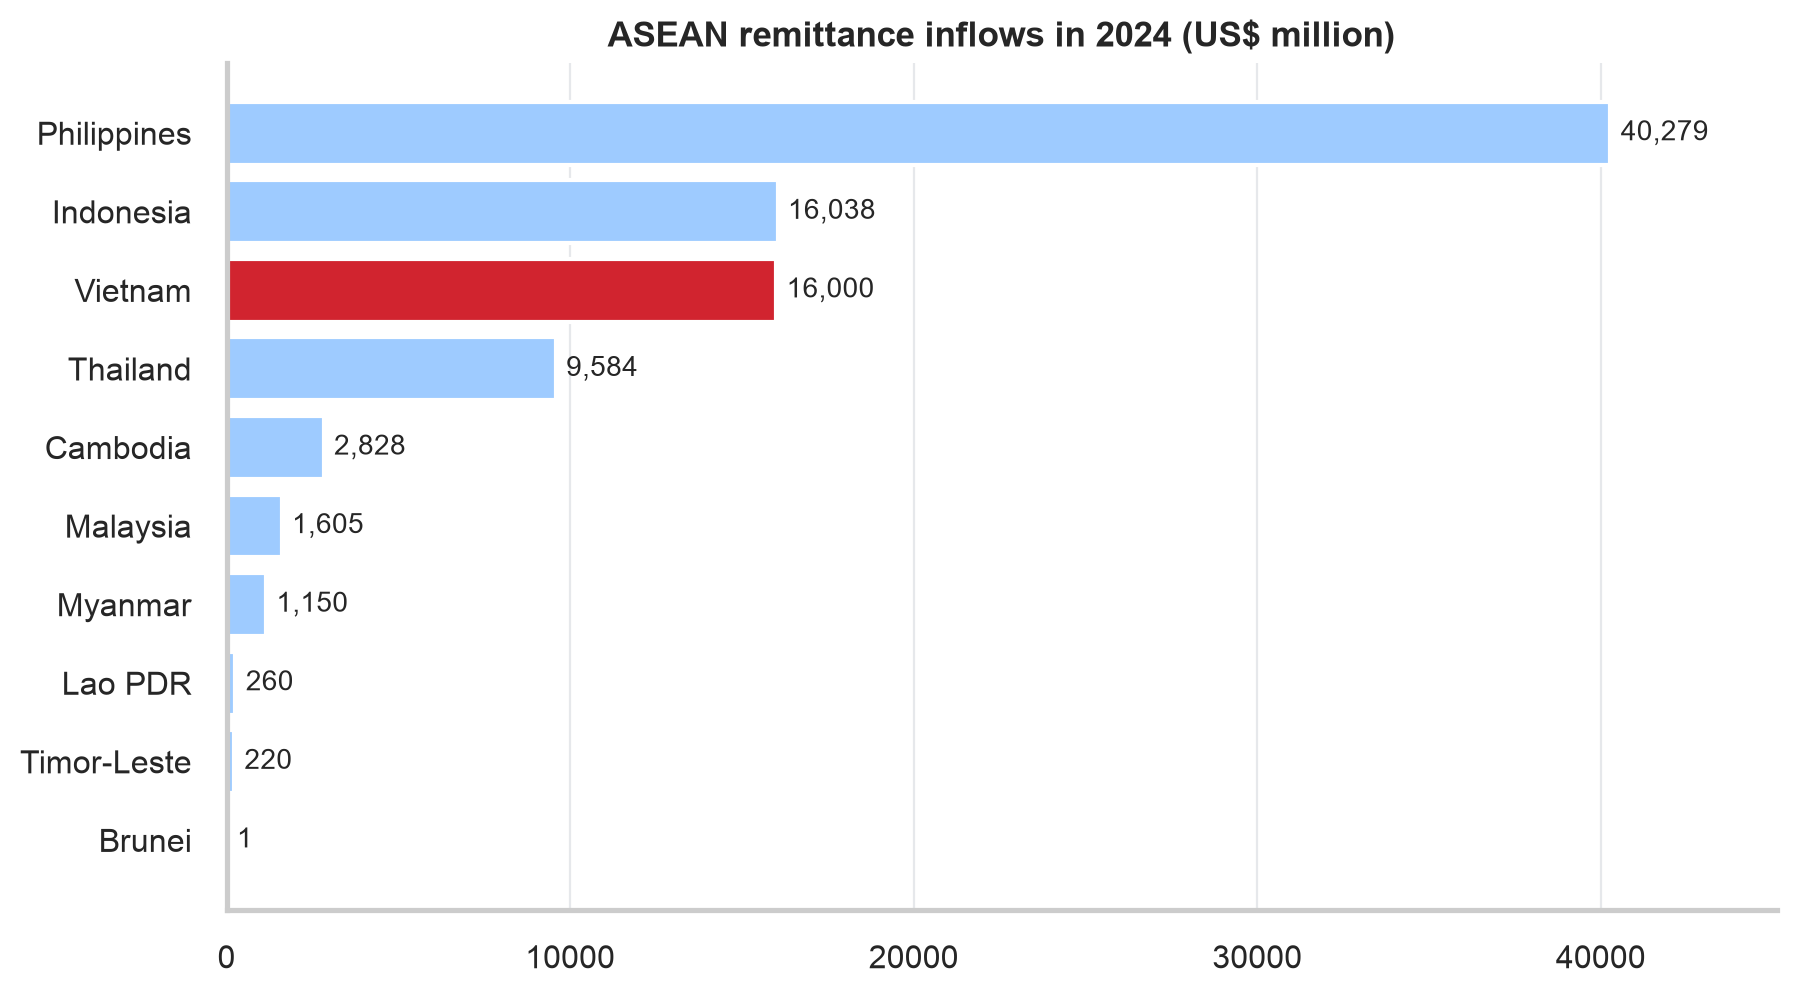

In [4]:
snap = analysis.asean_snapshot(panel)
display(snap)
display(Image(viz.asean_trends(panel)))
display(Image(viz.asean_2024_ranking(snap)))

In [5]:
analysis.asean_growth(panel)

,2000,2024,Multiple,CAGR_pct
Country,,,,
Cambodia,102.60,"2,827.92",27.56,14.82
Indonesia,"1,190.20","16,038.37",13.48,11.45
Myanmar,102.15,"1,150.00",11.26,10.61
Vietnam,"1,585.00","16,000.00",10.09,10.11
Philippines,"6,924.00","40,279.41",5.82,7.61
Thailand,"1,696.79","9,584.46",5.65,7.48
Malaysia,342.37,"1,605.28",4.69,6.65


Vietnam is **#3 in ASEAN** (practically tied with Indonesia at ~US$16bn, behind only the Philippines at ~US$40bn). It receives ~18% of all ASEAN remittances.

## 4. Extension: remittances relative to GDP

Vietnam: 5.1% of GDP in 2000, peak 8.0% in 2007, 3.4% in 2024 (2015-24 average 3.3%)


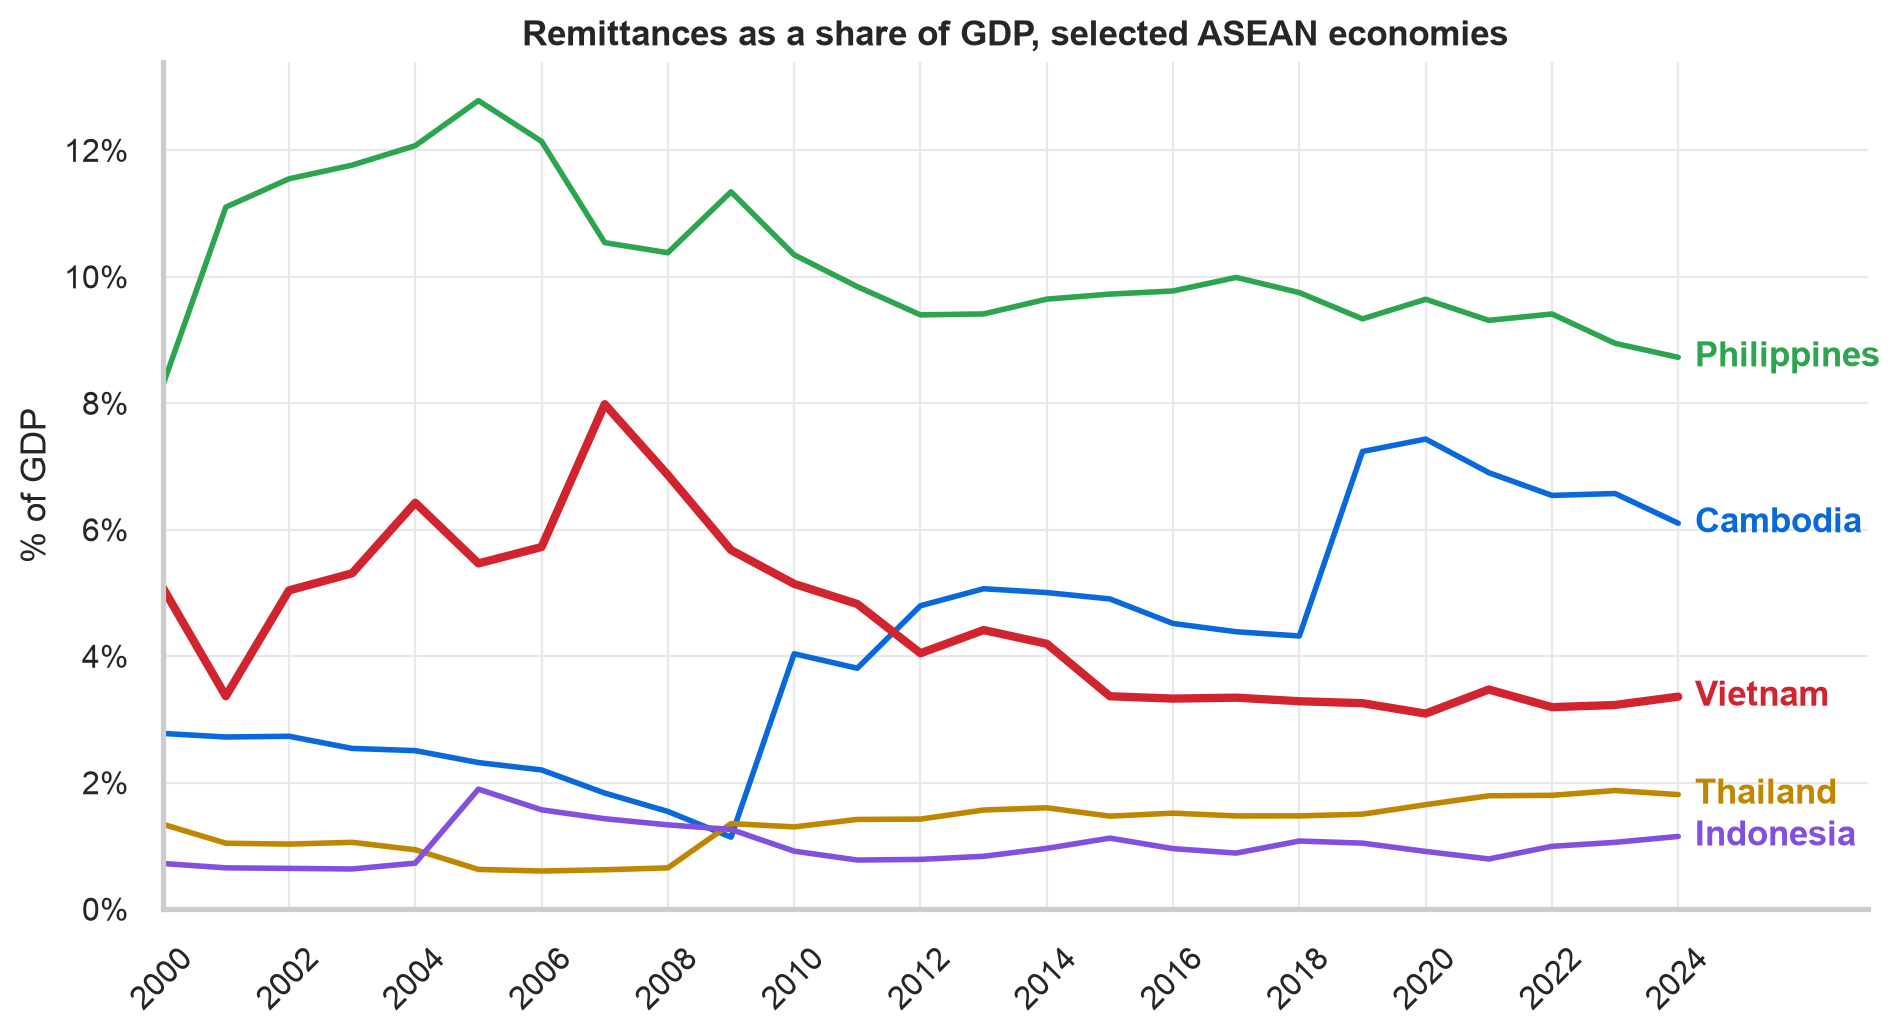

In [6]:
print(f"Vietnam: {h['remit_pct_gdp_start']:.1f}% of GDP in 2000, peak {h['remit_pct_gdp_peak']:.1f}% in "
      f"{h['remit_pct_gdp_peak_year']}, {h['remit_pct_gdp_end']:.1f}% in 2024 "
      f"(2015-24 average {h['remit_pct_gdp_mean_2015_2024']:.1f}%)")
display(Image(viz.remittance_gdp_share(panel)))

Remittances grew ~10x in dollars, but Vietnam's GDP grew ~15x, so the **share of GDP fell** from a 2007 peak near 8% to a stable ~3.3% since 2015. Remittances are a large and steady flow in absolute terms, but Vietnam is far less *dependent* on them than the Philippines (~9%) or Cambodia (~6%).

## Data notes
* KNOMAD records "not reported" as 0 for some economies (e.g. Singapore); zeros are treated as missing. Brunei's values (~US$1m) are effectively negligible.
* Cambodia's jump around 2019 (and Indonesia's in 2005) look like series revisions, so treat their growth multiples with caution.
* Remittance data covers 2000-2024; FDI and GDP come from World Bank WDI (current US$). FDI is net inflows (balance of payments), which can be volatile or negative.